In [1]:
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append("..")


from trips.test_problems.Tomography import Tomography
import astra

import jlinops


from rsolvers import RIASGKS, RMMGKS

In [2]:
# Define an object of the class Tomogrpahy
Tomo = Tomography ()
# Specify the dimensions of the phantom and the number of angels
nx = 100
ny = 100
views = 50
# Define the true solution throught the function gen_true ().
( x_true , nx , ny ) = Tomo.gen_true( test_problem = "tectonic", nx = nx , ny = ny)
# Define the forward operator
A = Tomo.forward_Op( nx , ny , views )
# Generate the data
(A , b_true , p , q , AforMatrixOperation ) = Tomo.gen_data( x_true , nx , ny , views )
# Add noise in the true simulated sinogram b_true
(b , delta ) = Tomo . add_noise ( b_true = b_true , opt = "Gaussian", noise_level= 0.001)

settings
no crime


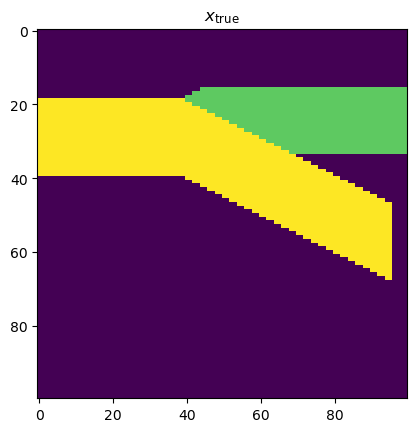

In [3]:
plt.imshow(x_true.reshape((nx,ny)))
plt.title("$x_{\\text{true}}$")
plt.show()

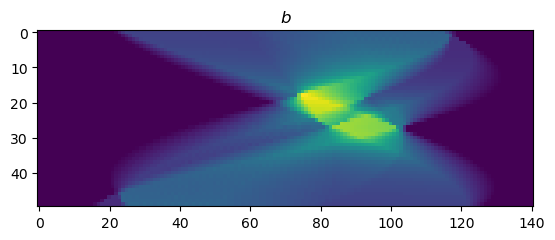

In [4]:
plt.imshow(b)
plt.title("$b$")
plt.show()

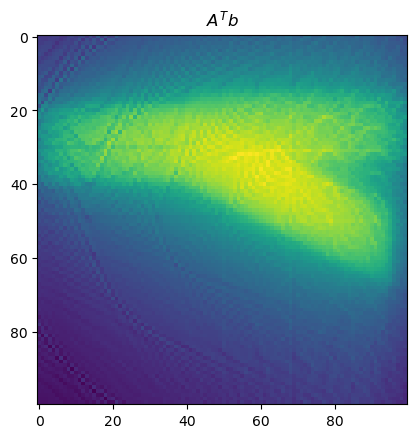

In [5]:
plt.imshow((A.T @ b.flatten()).reshape((nx,ny)))
plt.title("$A^T b$")
plt.show()

In [6]:
L = jlinops.Neumann2D((nx, ny)) # gradient regularization
#L = jlinops.IdentityOperator((M*N, M*N)) # identity regularization

rmmgks_solver = RMMGKS(A, L, b.flatten(), noise_var=delta**2)
#data = rmmgks_solver.solve(n_iter=200, init_dim=10, kmin=10, kmax=25, hyperpr_r=1.0, hyperpr_beta=1.5 + 1e-3, x_true=x_true, regparam="dp", eta=1.05)
data = rmmgks_solver.solve(n_iter=1000, init_dim=10, kmin=10, kmax=25, q=1.0, epsilon=1e-2, x_true=x_true, regparam="dp", eta=1.05)

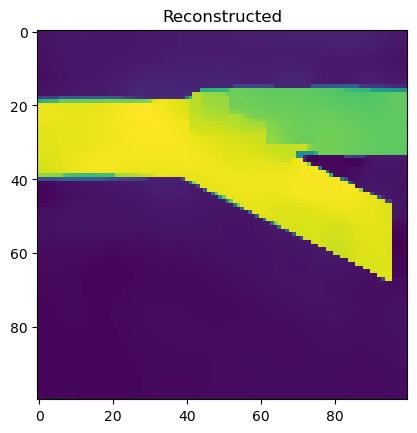

In [11]:
plt.imshow(data["x"].reshape((nx,ny)))
plt.title("Reconstructed")
plt.show()

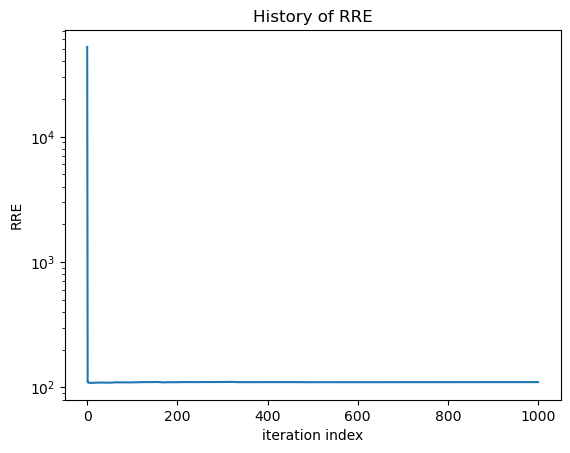

In [7]:
plt.plot(data["rre_history"])
plt.yscale("log")
plt.title("History of RRE")
plt.ylabel("RRE")
plt.xlabel("iteration index")
plt.show()

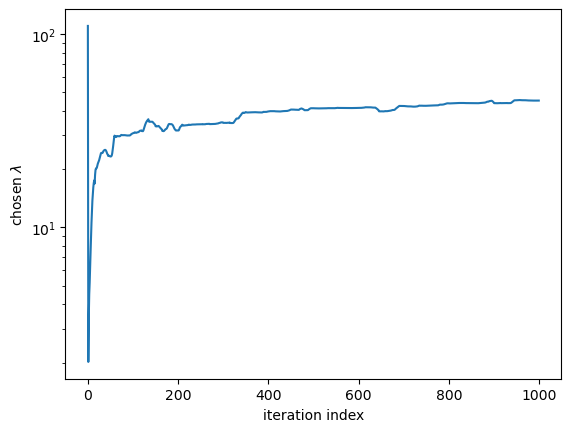

In [8]:
plt.plot(data["lambda_history"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("chosen $\\lambda$")
plt.show()

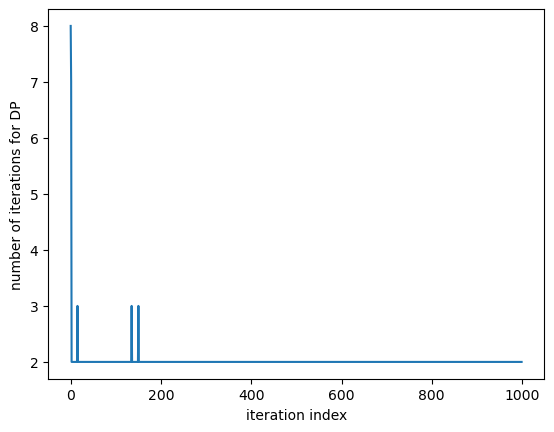

In [12]:
plt.plot(data["dp_cubic_n_iters"])
plt.xlabel("iteration index")
plt.ylabel("number of iterations for DP")
plt.show()

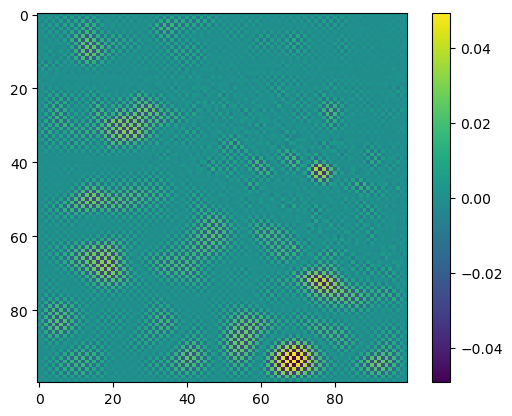

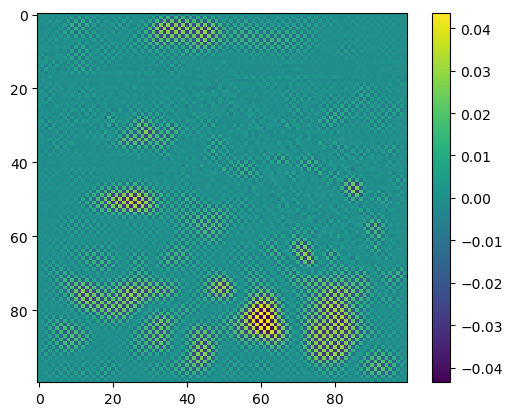

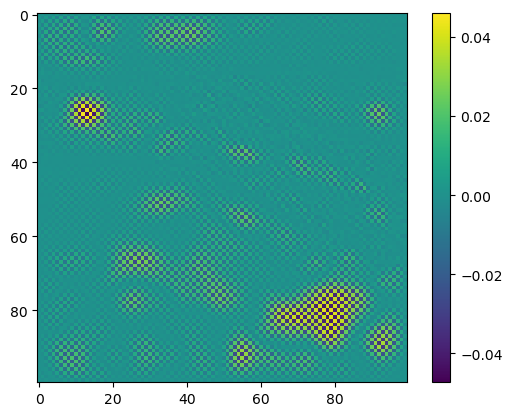

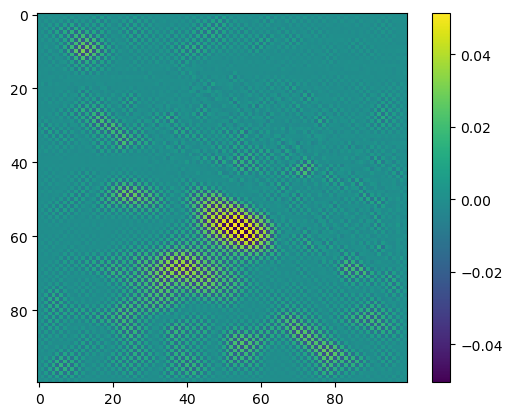

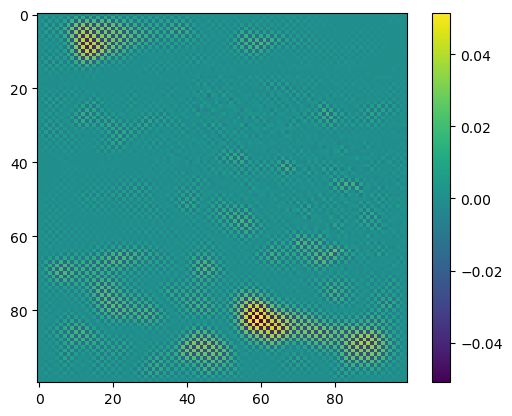

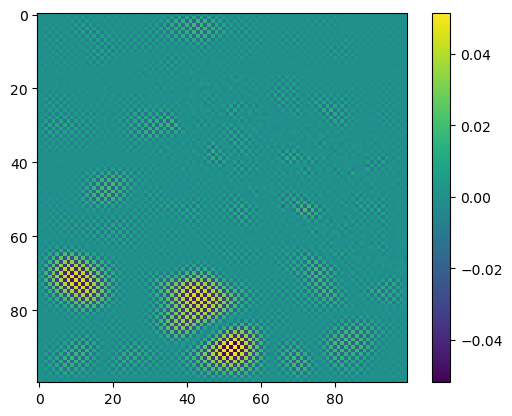

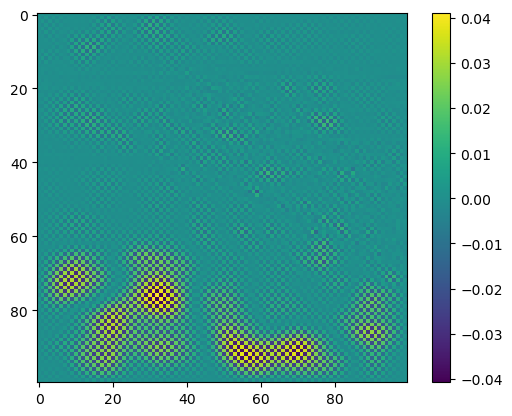

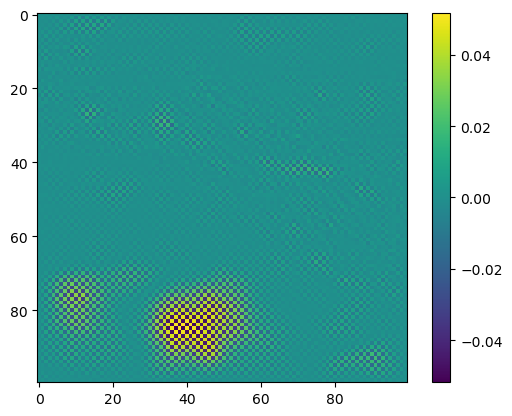

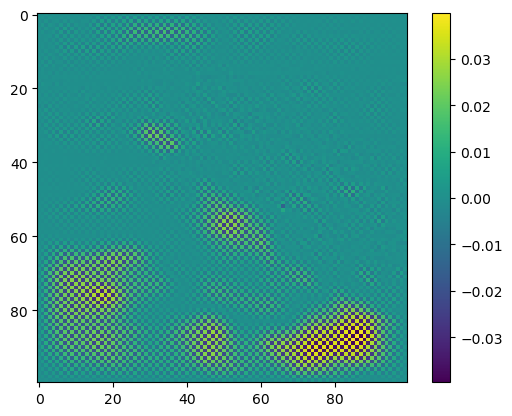

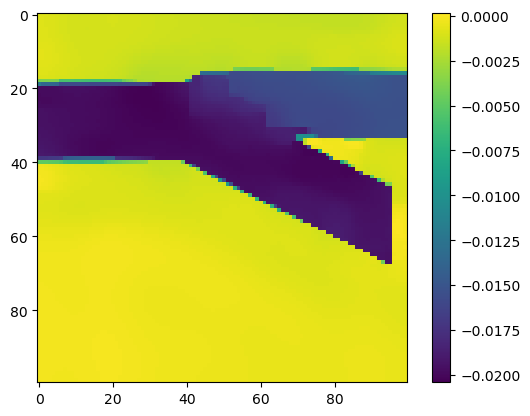

In [15]:
for j in range(10):
    tmp = data["V"][:,j].reshape((nx,ny))
    plt.figure()
    plt.imshow(tmp)
    plt.colorbar()